# 03 Loan amount: regression
New dataset: change `DATA` and `TARGET`.

## 1. Setup

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import friedmanchisquare, f_oneway, ttest_rel, wilcoxon
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

from sklearn.model_selection import KFold, RepeatedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures

In [2]:
DATA = "data/loan_data.csv"
TARGET = "loan_amount_sanctioned"
SCORING = "r2"

In [3]:
df = pd.read_csv(DATA)
df.shape

(600, 11)

## 2. EDA

In [4]:
df.head()

,Applicant_Income,Coapplicant_Income,Credit_Score,Loan_Amount_Term,Dependents,Education,Self_Employed,Property_Area,Existing_Loans,Age,loan_amount_sanctioned
0,6300.33,77.17,694,120,0,Graduate,No,Semiurban,3,33,3230.28
1,4586.48,2500.00,749,36,2,Graduate,No,Urban,0,52,2962.66
2,6794.33,2614.88,663,180,0,Graduate,No,Rural,1,35,3244.08
3,10525.07,2500.00,756,180,1,Not Graduate,No,Rural,1,56,3887.73
4,4371.77,2500.00,525,360,0,Graduate,No,Semiurban,3,25,2793.42


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Applicant_Income        600 non-null    float64
 1   Coapplicant_Income      600 non-null    float64
 2   Credit_Score            600 non-null    int64  
 3   Loan_Amount_Term        600 non-null    int64  
 4   Dependents              600 non-null    str    
 5   Education               600 non-null    str    
 6   Self_Employed           600 non-null    str    
 7   Property_Area           600 non-null    str    
 8   Existing_Loans          600 non-null    int64  
 9   Age                     600 non-null    int64  
 10  loan_amount_sanctioned  600 non-null    float64
dtypes: float64(3), int64(4), str(4)
memory usage: 51.7 KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Applicant_Income,600.0,5513.030850,3046.558905,972.01,3472.7225,4933.825,6711.5375,33737.52
Coapplicant_Income,600.0,1892.362417,1928.472629,0.00,31.5500,1542.535,2617.0375,6207.67
Credit_Score,600.0,580.450000,159.244085,300.00,441.0000,583.000,720.7500,849.00
Loan_Amount_Term,600.0,178.940000,120.450226,12.00,60.0000,180.000,360.0000,360.00
Existing_Loans,600.0,1.420000,1.102554,0.00,0.0000,1.000,2.0000,3.00
Age,600.0,43.528333,12.274376,21.00,33.0000,44.000,54.0000,64.00
loan_amount_sanctioned,600.0,2938.501483,1121.166668,1000.00,2197.9800,2736.495,3504.8375,8918.62


In [7]:
print(df.isnull().sum().sum())
print(df.duplicated().sum())

0
0


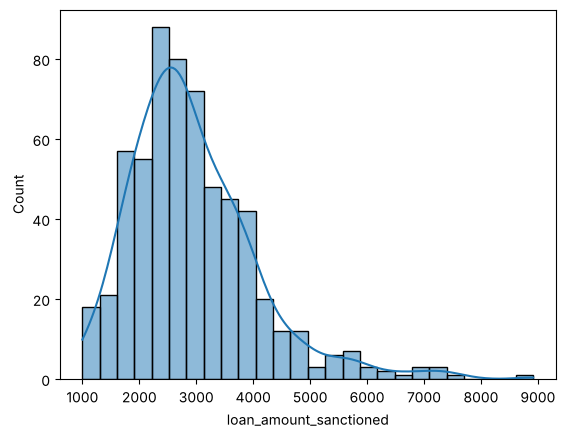

In [8]:
sns.histplot(df[TARGET], kde=True)
plt.show()

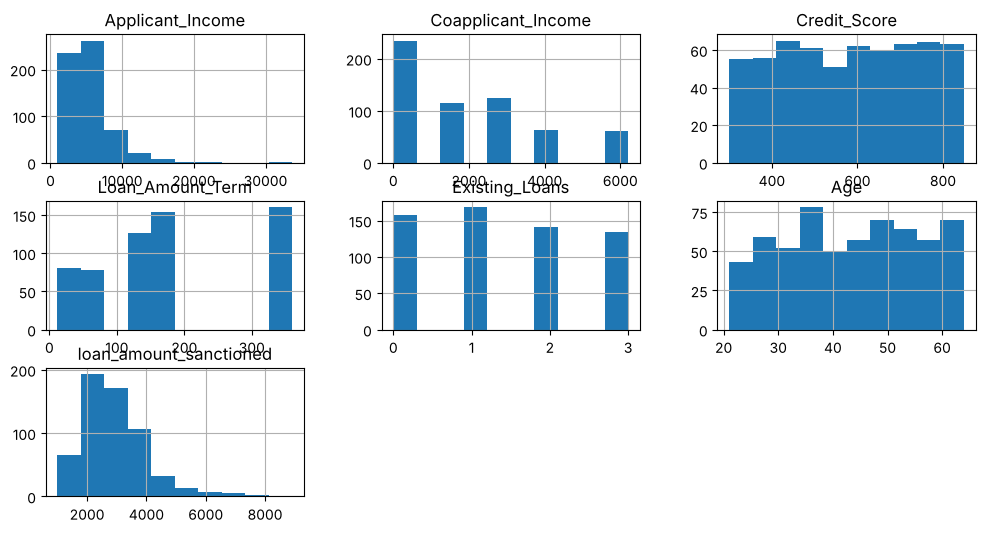

In [9]:
df.select_dtypes("number").iloc[:, :8].hist(figsize=(12, 6))
plt.show()

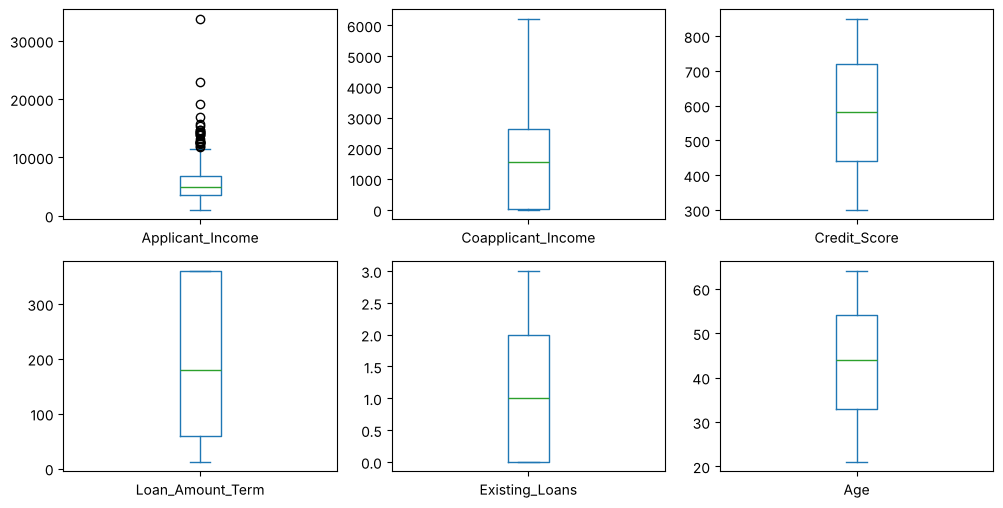

In [10]:
df.select_dtypes("number").iloc[:, :6].plot(
    kind="box", subplots=True, layout=(2, 3), figsize=(12, 6)
)
plt.show()

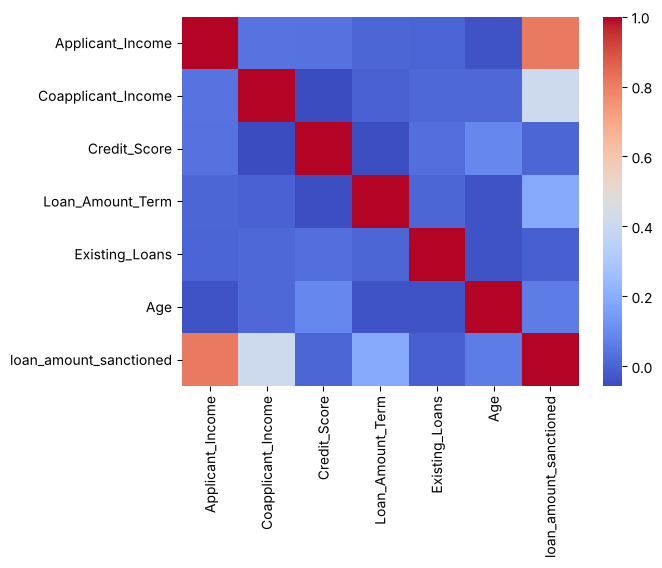

In [11]:
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")
plt.show()

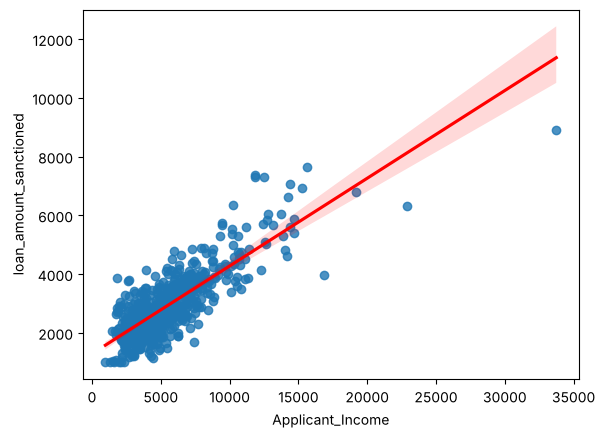

In [12]:
best_feature = df.corr(numeric_only=True)[TARGET].drop(TARGET).abs().idxmax()
sns.regplot(data=df, x=best_feature, y=TARGET, line_kws={"color": "red"})
plt.show()

## 3. Preprocessing

In [13]:
df = df.drop_duplicates()

In [14]:
for col in df.columns.drop(TARGET):
    if df[col].dtype.kind in "if":
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

In [15]:
X = pd.get_dummies(df.drop(columns=TARGET), drop_first=True)

In [16]:
y = df[TARGET]

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [19]:
def evaluate(model):
    pred = model.predict(X_test)
    n, p = X_test.shape
    mse = mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    print("MAE        :", round(mean_absolute_error(y_test, pred), 2))
    print("MSE        :", round(mse, 2))
    print("RMSE       :", round(np.sqrt(mse), 2))
    print("R2         :", round(r2, 4))
    print("Adjusted R2:", round(1 - (1 - r2) * (n - 1) / (n - p - 1), 4))

## 4. Linear Regression

In [20]:
lr = LinearRegression()
lr.fit(X_train, y_train)
evaluate(lr)

MAE        : 232.87
MSE        : 105517.58
RMSE       : 324.83
R2         : 0.9311
Adjusted R2: 0.9226


## 5. Ridge

In [21]:
ridge = Ridge()
ridge.fit(X_train, y_train)
evaluate(ridge)

MAE        : 232.93
MSE        : 105253.26
RMSE       : 324.43
R2         : 0.9313
Adjusted R2: 0.9228


In [22]:
ridge_grid = {
    "alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
}

In [23]:
ridge_gs = GridSearchCV(ridge, ridge_grid, cv=5, scoring=SCORING, n_jobs=-1)
ridge_gs.fit(X_train, y_train)
print(ridge_gs.best_params_)
print(ridge_gs.best_score_)

{'alpha': 1}
0.9242662481028214


In [24]:
best_ridge = ridge_gs.best_estimator_
evaluate(best_ridge)

MAE        : 232.93
MSE        : 105253.26
RMSE       : 324.43
R2         : 0.9313
Adjusted R2: 0.9228


## 6. Lasso

In [25]:
lasso = Lasso(max_iter=10000)
lasso.fit(X_train, y_train)
evaluate(lasso)

MAE        : 232.77
MSE        : 105664.61
RMSE       : 325.06
R2         : 0.931
Adjusted R2: 0.9225


In [26]:
lasso_grid = {
    "alpha": [0.001, 0.01, 0.1, 1, 10, 100],
}

In [27]:
lasso_gs = GridSearchCV(lasso, lasso_grid, cv=5, scoring=SCORING, n_jobs=-1)
lasso_gs.fit(X_train, y_train)
print(lasso_gs.best_params_)
print(lasso_gs.best_score_)

{'alpha': 1}
0.9243536158089946


In [28]:
best_lasso = lasso_gs.best_estimator_
evaluate(best_lasso)

MAE        : 232.77
MSE        : 105664.61
RMSE       : 325.06
R2         : 0.931
Adjusted R2: 0.9225


In [29]:
coefs = pd.DataFrame(
    {"Linear": lr.coef_, "Ridge": best_ridge.coef_, "Lasso": best_lasso.coef_},
    index=X.columns,
)
print(coefs.round(1))

                         Linear  Ridge  Lasso
Applicant_Income          878.1  876.2  876.8
Coapplicant_Income        452.3  451.4  451.4
Credit_Score               -1.2   -1.3   -0.2
Loan_Amount_Term          199.9  199.5  199.0
Existing_Loans            -12.1  -12.1  -11.1
Age                       106.7  106.4  105.6
Dependents_1               -4.4   -4.5   -4.1
Dependents_2               10.0   10.0    9.1
Dependents_3+               7.7    7.7    6.6
Education_Not Graduate   -287.8 -287.0 -286.5
Self_Employed_Yes         -47.9  -47.8  -46.8
Property_Area_Semiurban   109.5  108.3  106.8
Property_Area_Urban       184.9  183.7  182.3


## 7. ElasticNet

In [30]:
enet = ElasticNet(max_iter=10000)
enet.fit(X_train, y_train)
evaluate(enet)

MAE        : 373.92
MSE        : 248090.42
RMSE       : 498.09
R2         : 0.838
Adjusted R2: 0.8181


In [31]:
enet_grid = {
    "alpha": [0.001, 0.01, 0.1, 1, 10],
    "l1_ratio": [0.2, 0.5, 0.8],
}

In [32]:
enet_gs = GridSearchCV(enet, enet_grid, cv=5, scoring=SCORING, n_jobs=-1)
enet_gs.fit(X_train, y_train)
print(enet_gs.best_params_)
print(enet_gs.best_score_)

{'alpha': 0.01, 'l1_ratio': 0.5}
0.924283266919466


In [33]:
best_enet = enet_gs.best_estimator_
evaluate(best_enet)

MAE        : 233.11
MSE        : 104913.91
RMSE       : 323.9
R2         : 0.9315
Adjusted R2: 0.9231


## 8. Random Forest

In [34]:
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
evaluate(rf)

MAE        : 345.67
MSE        : 243094.53
RMSE       : 493.05
R2         : 0.8413
Adjusted R2: 0.8218


In [35]:
rf_grid = {
    "n_estimators": [50, 100],
    "max_depth": [None, 5, 10],
    "max_features": [1.0, "sqrt"],
    "min_samples_split": [2, 5],
}

In [36]:
rf_gs = GridSearchCV(rf, rf_grid, cv=5, scoring=SCORING, n_jobs=-1)
rf_gs.fit(X_train, y_train)
print(rf_gs.best_params_)
print(rf_gs.best_score_)

{'max_depth': None, 'max_features': 1.0, 'min_samples_split': 5, 'n_estimators': 50}
0.8363376218624182


In [37]:
best_rf = rf_gs.best_estimator_
evaluate(best_rf)

MAE        : 352.68
MSE        : 258107.98
RMSE       : 508.04
R2         : 0.8314
Adjusted R2: 0.8108


## 9. Grid Search vs Random Search

In [38]:
start = time.time()
grid_search = GridSearchCV(rf, rf_grid, cv=5, scoring=SCORING)
grid_search.fit(X_train, y_train)
grid_time = time.time() - start

In [39]:
start = time.time()
random_search = RandomizedSearchCV(
    rf,
    rf_grid,
    n_iter=8,
    cv=5,
    scoring=SCORING,
    random_state=42,
)
random_search.fit(X_train, y_train)
random_time = time.time() - start

In [40]:
print("Grid combinations:", len(grid_search.cv_results_["params"]))
print("Grid best score:", round(grid_search.best_score_, 4))
print("Grid time:", round(grid_time, 2))
print("Random combinations:", len(random_search.cv_results_["params"]))
print("Random best score:", round(random_search.best_score_, 4))
print("Random time:", round(random_time, 2))

Grid combinations: 24
Grid best score: 0.8363
Grid time: 12.94
Random combinations: 8
Random best score: 0.8362
Random time: 4.51


In [41]:
results = pd.DataFrame(grid_search.cv_results_)
fold_cols = [c for c in results.columns if c.startswith("split")]
print(results.loc[grid_search.best_index_, fold_cols])

split0_test_score    0.798066
split1_test_score    0.817101
split2_test_score    0.838241
split3_test_score    0.858971
split4_test_score    0.869307
Name: 2, dtype: float64


## 10. 5-fold Cross-Validation

In [42]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)

In [43]:
models = {
    "Linear": lr,
    "Ridge": best_ridge,
    "Lasso": best_lasso,
    "ElasticNet": best_enet,
    "Random Forest": best_rf,
}

In [44]:
for name, model in models.items():
    s = cross_val_score(model, X_train, y_train, cv=cv5, scoring=SCORING)
    print(
        name,
        s.round(3),
        "mean:",
        round(s.mean(), 4),
        "std:",
        round(s.std(), 4),
    )

Linear [0.918 0.902 0.944 0.934 0.926] mean: 0.9249 std: 0.0143
Ridge [0.918 0.902 0.944 0.934 0.927] mean: 0.9249 std: 0.0145
Lasso [0.918 0.902 0.945 0.934 0.927] mean: 0.9251 std: 0.0145
ElasticNet [0.918 0.901 0.944 0.935 0.927] mean: 0.9249 std: 0.0146


Random Forest [0.827 0.791 0.878 0.847 0.834] mean: 0.8353 std: 0.0281


## 11. PCA vs No PCA

In [45]:
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print(X_train.shape[1], "->", pca.n_components_)

13 -> 12


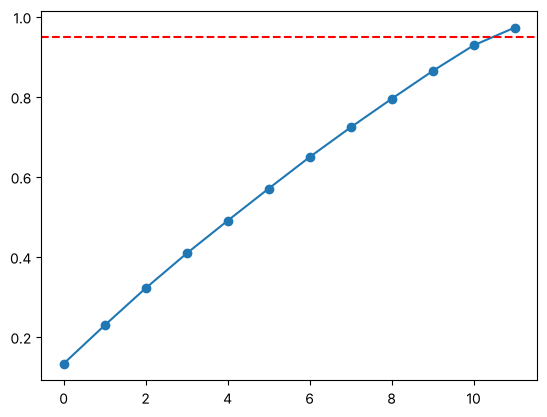

In [46]:
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.axhline(0.95, color="red", linestyle="--")
plt.show()

In [47]:
for name, model in models.items():
    no_pca = cross_val_score(
        model, X_train, y_train, cv=cv5, scoring=SCORING
    ).mean()
    with_pca = cross_val_score(
        model, X_train_pca, y_train, cv=cv5, scoring=SCORING
    ).mean()
    print(name, "| no PCA:", round(no_pca, 4), "| PCA:", round(with_pca, 4))

Linear | no PCA: 0.9249 | PCA: 0.8854
Ridge | no PCA: 0.9249 | PCA: 0.8855
Lasso | no PCA: 0.9251 | PCA: 0.8856
ElasticNet | no PCA: 0.9249 | PCA: 0.8855


Random Forest | no PCA: 0.8353 | PCA: 0.7119


## 12. Statistical Significance

In [48]:
repeated_cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

In [49]:
scores = {}
for name, model in models.items():
    scores[name] = cross_val_score(
        model, X_train, y_train, cv=repeated_cv, scoring=SCORING
    )
model_names = list(scores)
model_scores = list(scores.values())
print(pd.DataFrame(scores).mean().round(4))

Linear           0.9253
Ridge            0.9253
Lasso            0.9255
ElasticNet       0.9253
Random Forest    0.8354
dtype: float64


In [50]:
print("Friedman p:", friedmanchisquare(*model_scores)[1])
print("ANOVA p:", f_oneway(*model_scores)[1])

Friedman p: 1.0467389909964399e-06
ANOVA p: 1.0763744193625855e-25


In [51]:
means = [s.mean() for s in model_scores]
best = int(np.argmax(means))
print("Best model:", model_names[best])

Best model: Lasso


In [52]:
alpha = 0.05 / (len(model_names) - 1)
for i in range(len(model_names)):
    if i == best:
        continue
    t_p = ttest_rel(model_scores[best], model_scores[i])[1]
    w_p = wilcoxon(model_scores[best], model_scores[i])[1]
    print(model_names[best], "vs", model_names[i])
    print("t-test p:", round(t_p, 4))
    print("wilcoxon p:", round(w_p, 4))
    print("significant:", max(t_p, w_p) < alpha)

Lasso vs Linear
t-test p: 0.0482
wilcoxon p: 0.0353
significant: False
Lasso vs Ridge
t-test p: 0.0214
wilcoxon p: 0.0256
significant: False
Lasso vs ElasticNet
t-test p: 0.2033
wilcoxon p: 0.2293
significant: False
Lasso vs Random Forest
t-test p: 0.0
wilcoxon p: 0.0001
significant: True


## 13. Polynomial Features

In [53]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
print(X_train.shape[1], "->", X_train_poly.shape[1])

13 -> 104


In [54]:
poly_ridge = Ridge(alpha=10)
poly_ridge.fit(X_train_poly, y_train)
print("Linear R2:", round(lr.score(X_test, y_test), 4))
print("Poly R2:", round(poly_ridge.score(X_test_poly, y_test), 4))

Linear R2: 0.9311
Poly R2: 0.9472


## 14. Final Evaluation

In [55]:
best_model = models[model_names[best]]
pred = best_model.predict(X_test)
residuals = y_test - pred

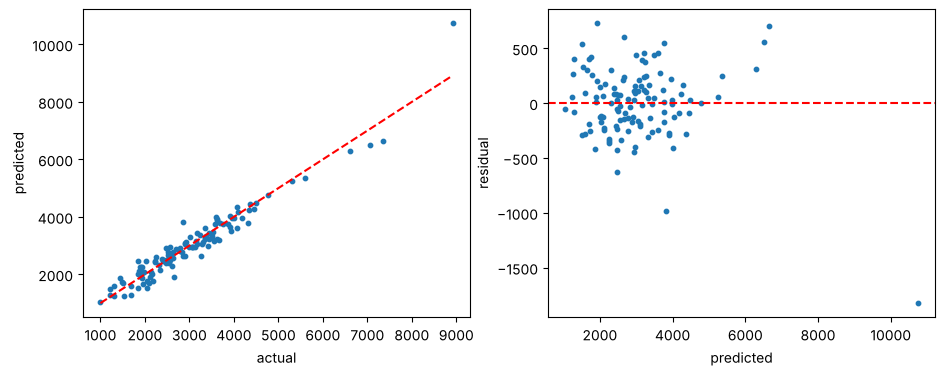

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_test, pred, s=10)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
ax[0].set(xlabel="actual", ylabel="predicted")
ax[1].scatter(pred, residuals, s=10)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set(xlabel="predicted", ylabel="residual")
plt.show()